# Load the current 3-channel autoencoder


The current model in the historical `pvcracks.vae` namespace is
`UNetAutoencoder3CHPlus`, a deterministic skip-connected autoencoder. It
reconstructs **crack, busbar, dark** binary masks in that order, with shape
`[N, 3, 400, 400]`, and produces 320 pooled bottleneck values. It needs
encoder skip features to reconstruct an image; random latent decoding is
unavailable.

Install the runtime from this checkout with `python -m pip install -e .`.
The matching checkpoint and all three XGBoost models ship with the package.
These examples use the 26 module 209 masks successfully segmented by the
supplied FinalVAE3CH analysis. No Box folder or training package is required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pvcracks.vae import load_unet_ae_crack_plus
from pvcracks.vae.features import CHANNELS, extract_features
from pvcracks.vae.inference import reconstruct_masks, reconstruction_scores

# Works from the repository root, docs/Examples, or a notebook subdirectory.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "docs/data/autoencoder_3ch_module_209.npz").is_file())
DATA = ROOT / "docs/data"
DEVICE = "cpu"  # Set to "cuda" if desired.
BATCH_SIZE = 4
masks = np.load(DATA / "autoencoder_3ch_module_209.npz")["masks"]
metadata = pd.read_csv(DATA / "autoencoder_3ch_module_209.csv")
model, checkpoint = load_unet_ae_crack_plus(device=DEVICE)
print(f"{len(masks)} masks; input {masks.shape[1:]}; embedding {model.latent_dim}")

26 masks; input (3, 400, 400); embedding 320


## Reconstruct masks and inspect the bottleneck

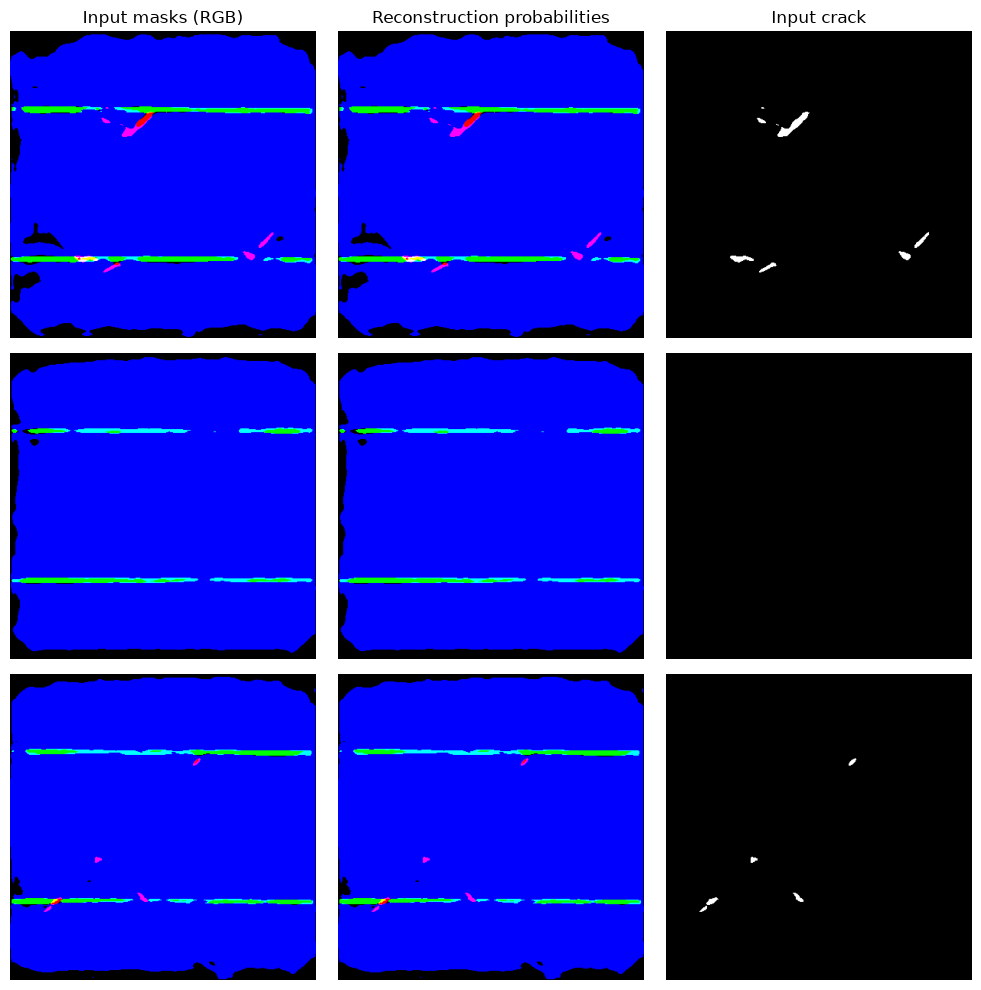

In [2]:
probabilities = reconstruct_masks(model, masks[:3], batch_size=BATCH_SIZE)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row in range(3):
    axes[row, 0].imshow(masks[row].astype(np.float32).transpose(1, 2, 0))
    axes[row, 1].imshow(probabilities[row].numpy().transpose(1, 2, 0))
    axes[row, 2].imshow(masks[row, 0], cmap="gray")
    for ax in axes[row]:
        ax.set_axis_off()
for ax, title in zip(axes[0], ["Input masks (RGB)", "Reconstruction probabilities", "Input crack"]):
    ax.set_title(title)
fig.tight_layout()
plt.show()

In [3]:
features = extract_features(model, masks, batch_size=BATCH_SIZE)
display(features.head())
assert features.shape == (len(masks), 326)

,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6,latent_7,latent_8,latent_9,...,latent_316,latent_317,latent_318,latent_319,crack_fraction,busbar_fraction,dark_fraction,crack_components,busbar_components,dark_components
0,0.084619,-0.106602,-0.093527,0.014012,0.012016,-0.143547,0.073016,0.776081,0.175180,2.137794,...,-0.090595,-0.129869,0.037698,0.110867,0.005962,0.028925,0.891619,8,7,4
1,0.077738,-0.103067,-0.127785,0.016810,-0.010903,-0.182990,0.050297,0.900329,0.157293,2.510081,...,-0.105811,-0.123221,0.064560,0.079037,0.000000,0.024294,0.904106,0,7,1
2,0.090043,-0.105250,-0.114676,0.017243,0.002751,-0.152857,0.072750,0.833377,0.200408,2.295091,...,-0.102466,-0.127342,0.053567,0.117861,0.001856,0.025406,0.915563,5,7,3
3,0.085793,-0.105952,-0.125569,0.015031,-0.018717,-0.172385,0.058232,0.880672,0.158139,2.474941,...,-0.104969,-0.125783,0.066530,0.081366,0.000412,0.017887,0.922300,3,10,3
4,0.076993,-0.104716,-0.128640,0.009969,-0.015540,-0.182519,0.043804,0.884191,0.157250,2.505773,...,-0.109308,-0.124893,0.064141,0.073465,0.000000,0.028812,0.892362,0,4,2


`latent_0` through `latent_319` are unscaled embeddings. The remaining
columns are fractions and 8-connected component counts from the original
masks. Keep this complete table for the matching XGBoost models.

The bundled checkpoint is the exported best state from fold 5, epoch 299,
as saved by the supplied training script. See `training/README.md` for
retraining and `pvcracks/vae/model_manifest.json` for artifact provenance.